# Using scVI Embeddings in SpatialZoomer

This tutorial contains two parts:

1. Compute the scVI embedding in an environment with `scvi-tools`.
2. Load the embedding in a SpatialZoomer environment for multiscale spatial analysis.

PCA and ICA examples are provided in `Tutorial3_Alternative_Low_Dimensional_Embeddings_PCA_ICA.ipynb`.

## Table of Contents

* [1. Compute the scVI embedding](#1-compute-the-scvi-embedding)
* [2. Run SpatialZoomer](#2-run-spatialzoomer)


## 1. Compute the scVI embedding

This tutorial uses the Alzheimer’s disease dataset from Figure 2.

The dataset contains six Xenium v1 mouse brain samples profiled with a 347-gene panel: three wild-type samples (`WT1–WT3`) and three TgCRND8 Alzheimer’s disease model samples (`Tg1–Tg3`). The samples represent mild, moderate, and advanced stages of amyloid-beta deposition.

The processed AnnData object can be downloaded from [Google Cloud](https://drive.google.com/file/d/19iSZ3OHdBq2nldGF6OG5SaIeEblqRBXO/view?usp=drive_link) or from the `Figure2_Xenium_v1_Alzheimers_Disease_Progression` folder on Zenodo repository.

The original dataset is available from the [10x Genomics website](https://www.10xgenomics.com/datasets/xenium-in-situ-analysis-of-alzheimers-disease-mouse-model-brain-coronal-sections-from-one-hemisphere-over-a-time-course-1-standard).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import scanpy as sc
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

runLabel = 'Xenium_V1_AD_Merged'
save_path = './Outputs/' + runLabel+'_scVI_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad("Figure2_AD.h5ad")
adata

AnnData object with n_obs × n_vars = 349063 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'batch_colors'
    obsm: 'spatial', 'spatial_raw'

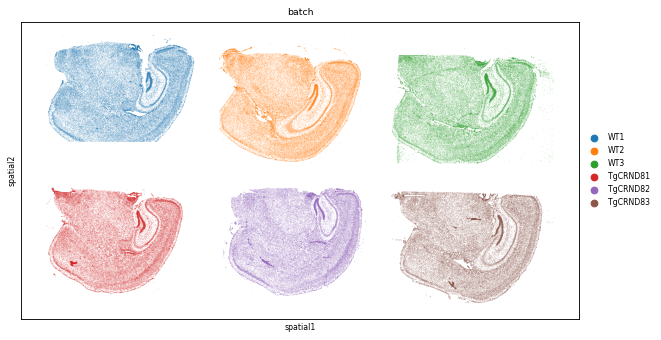

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6), dpi= use_dpi)

sc.pl.embedding(
    adata,
    basis="spatial", 
    color="batch",
    ax=ax,
    show=False,
)

ax.set_aspect("equal")
ax.invert_yaxis()      
plt.show()

### Install scvi-tools

Install `scvi-tools` in a separate environment:

```bash
pip install scvi-tools
```

For additional installation options, see the [scvi-tools repository](https://github.com/scverse/scvi-tools).


In [3]:
import scvi

def scvi_train(adata):
    adata.raw = adata
    sc.pp.highly_variable_genes(
        adata,
        flavor="seurat_v3",
        n_top_genes=2000,
        layer="counts",
        batch_key="batch",
        subset=True,
        span=0.5
    )
    scvi.model.SCVI.setup_anndata(
        adata, 
        layer="counts", 
        batch_key="batch", 
    )
    vae = scvi.model.SCVI(
        adata,
        n_layers=2,
        n_latent=50,
        gene_likelihood="nb",
    )
    vae.train()
    return vae


adata.layers["counts"] = adata.X.copy()
vae = scvi_train(adata)
vae.save(save_path, overwrite=True)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Epoch 23/23: 100%|██████████| 23/23 [11:42<00:00, 30.34s/it, v_num=1, train_loss_step=181, train_loss_epoch=186]

`Trainer.fit` stopped: `max_epochs=23` reached.


Epoch 23/23: 100%|██████████| 23/23 [11:42<00:00, 30.53s/it, v_num=1, train_loss_step=181, train_loss_epoch=186]


In [4]:
import numpy as np

scvi_embedding = vae.get_latent_representation()
np.savetxt(
    save_path + runLabel + "_scvi_embeddings.txt",
    scvi_embedding,
    delimiter="\t"
)
scvi_embedding.shape

(349063, 50)

## 2. Run SpatialZoomer

Switch to an environment with SpatialZoomer installed.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import squidpy as sq
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

In [ ]:
runLabel = 'Xenium_V1_AD_Merged'
save_path = './Outputs/' + runLabel+'_scVI_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad("Figure2_AD.h5ad")
adata = sz.Preprocess(adata)
adata

AnnData object with n_obs × n_vars = 349063 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'batch_colors', 'log1p'
    obsm: 'spatial', 'spatial_raw'
    layers: 'counts'

Load the precomputed scVI embedding and store it in `adata.obsm["X_scvi"]`.

In [ ]:
X_scvi = np.loadtxt(
    save_path + runLabel + "_scvi_embeddings.txt",
    delimiter="\t"
)

adata.obsm["X_scvi"] = X_scvi.copy()
X_scvi.shape

(349063, 50)

Set `use_rep="X_scvi"` in `sz_analyzer.multiscale_transform()` to use the scVI embedding for multiscale spatial analysis.

Median similarities:  4.999999999984118
Time taken to construct spatial_knn: 2.2011 seconds
Time taken to perform spectral graph filter bank: 386.5179 seconds
Transformed signals saved to ./Outputs/Xenium_V1_AD_Merged_scVI_SpatialZoomer//Xenium_V1_AD_Merged_transformed_signals.h5


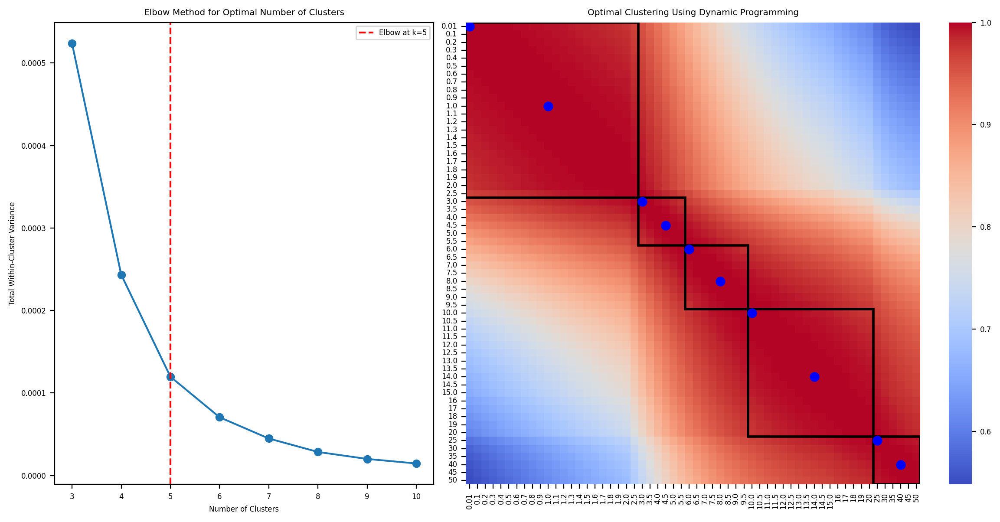

The optimal number of clusters is: 5
Typical scales: [0.01, 1.0, 3.0, 4.5, 6.0, 8.0, 10.0, 14.0, 25, 40]
Time taken to perform identification of typical scales: 23.3837 seconds
Time taken to perform UMAP and clustering for raw signal: 106.0851 seconds
Time taken to perform clustering for signal at scale 0.01: 85.8743 seconds
Time taken to perform clustering for signal at scale 1.0: 83.6768 seconds
Time taken to perform clustering for signal at scale 3.0: 75.3547 seconds
Time taken to perform clustering for signal at scale 4.5: 70.7398 seconds
Time taken to perform clustering for signal at scale 6.0: 70.1476 seconds
Time taken to perform clustering for signal at scale 8.0: 74.1583 seconds
Total time: 460.6548 seconds


AnnData object with n_obs × n_vars = 349063 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'leiden_Raw_res1.2', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'leiden_scale0.01_res1.2', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'leiden_scale1.0_res1.2', 'Kmeans_scale3.0', 'leiden_scale3.0_res0.8', 'leiden_scale3.0_res1', 'leiden_scale3.0_res1.2', 'Kmeans_scale4.5', 'leiden_scale4.5_res0.8', 'leiden_scale4.5_res1', 'leiden_scale4.5_res1.2', 'Kmeans_scale6.0', 'leiden_scale6.0_res0.8', 'leiden_scale6.0_res1', 'leiden

In [4]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)

# define scales
scales = [0.01] + np.arange(0.1, 2.1, 0.1).tolist() + np.arange(2.5, 15.5, 0.5).tolist() + np.arange(16, 21, 1).tolist() +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

# if not passing the parameter scales, scales are automatically generated as above
sz_analyzer.multiscale_transform(use_rep='X_scvi', n_neighbors=20, scales=scales)
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)
resolutions = [0.8, 1, 1.2]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions, min_scale=None, max_scale=8)
sz_analyzer.adata.write(save_path + runLabel + '_scVI_SpatialZoomer.h5ad')
sz_analyzer.adata

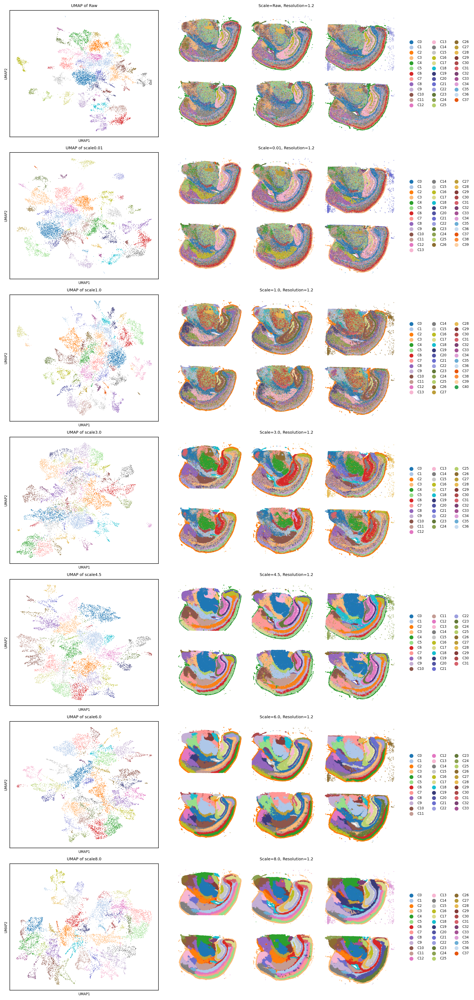

In [5]:
sz_analyzer.plot_multiscale_clusters(resolution=1.2, figsize=(12, 25), pt_size_umap= 1, pt_size_scatter= 0.1)